In [6]:
import polars as pl
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

In [7]:
GOLD_PATH = Path("../data/3_gold/weekly_demand_features_calendar_fixed.parquet")

df = pl.read_parquet(GOLD_PATH)

print("Shape:", df.shape)
print("Unique SKUs:", df["StockCode"].n_unique())
print("Date range:", df["Week_Start"].min(), "->", df["Week_Start"].max())
print("Target date range:", df["Target_Week_Start"].min(), "->", df["Target_Week_Start"].max())

Shape: (307656, 20)
Unique SKUs: 4622
Date range: 2009-12-28 00:00:00 -> 2011-11-28 00:00:00
Target date range: 2010-01-04 00:00:00 -> 2011-12-05 00:00:00


Bước 2 — Chọn mốc chia Train/Test

In [8]:
print("Số tuần:", df["Week_Start"].n_unique())
print("\nPhân bố số dòng theo năm:")
display(
    df.group_by(pl.col("Target_Week_Start").dt.year().alias("Year"))
    .agg([
        pl.col("Target_Week_Start").n_unique().alias("Weeks"),
        pl.len().alias("Rows")
    ])
    .sort("Year")
)

Số tuần: 101

Phân bố số dòng theo năm:


Year,Weeks,Rows
i32,u32,u32
2010,52,161730
2011,49,145926


Bước 3 — Xác định mốc chia dữ liệu

In [9]:
target_weeks = df["Target_Week_Start"].unique().sort()

split_idx = int(len(target_weeks) * 0.8)
split_date = target_weeks[split_idx]

print("Total target weeks:", len(target_weeks))
print("Split date:", split_date)
print("Train target weeks:", split_idx)
print("Test target weeks:", len(target_weeks) - split_idx)

Total target weeks: 101
Split date: 2011-07-18 00:00:00
Train target weeks: 80
Test target weeks: 21


Bước 4 — Chọn Top 20 SKU và chia Train/Test

In [10]:
# 1. Chỉ dùng dữ liệu Train để xếp hạng SKU
df_train_period = df.filter(pl.col("Target_Week_Start") < split_date)

top_20_skus = (
    df_train_period.group_by("StockCode")
    .agg(pl.col("Weekly_Demand").sum().alias("Total_Demand"))
    .sort("Total_Demand", descending=True)
    .head(20)["StockCode"]
)

# 2. Lọc Top 20 SKU
df_selected = df.filter(pl.col("StockCode").is_in(top_20_skus))

# 3. Chia theo Target_Week_Start
train_df = df_selected.filter(pl.col("Target_Week_Start") < split_date)
test_df = df_selected.filter(pl.col("Target_Week_Start") >= split_date)

print("Top 20 SKUs:", len(top_20_skus))
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Train target range:", train_df["Target_Week_Start"].min(), "->", train_df["Target_Week_Start"].max())
print("Test target range:", test_df["Target_Week_Start"].min(), "->", test_df["Target_Week_Start"].max())

Top 20 SKUs: 20
Train shape: (1577, 20)
Test shape: (420, 20)
Train target range: 2010-01-04 00:00:00 -> 2011-07-11 00:00:00
Test target range: 2011-07-18 00:00:00 -> 2011-12-05 00:00:00


/tmp/ipykernel_101578/3260022689.py:12: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  df_selected = df.filter(pl.col("StockCode").is_in(top_20_skus))


In [ ]:
#1. Sửa DeprecationWarning
df_selected = df.filter(
    pl.col("StockCode").is_in(top_20_skus.implode())
)

In [12]:
FEATURES = [
    "Lag_1W", "Lag_2W", "Lag_4W",
    "Rolling_Mean_4W", "Rolling_Std_4W",
    "Demand_Trend_Ratio", "Demand_CV",
    "Price_Ratio_Vs_Avg", "Avg_UnitPrice",
    "Month", "Quarter", "Year", "Is_Peak_Season"
]

TARGET = "Target_Demand_Weekly"

for name, data in [("TRAIN", train_df), ("TEST", test_df)]:
    print(f"\n===== {name} =====")
    display(data.select([
        pl.col(c).null_count().alias(c) for c in FEATURES + [TARGET]
    ]))


===== TRAIN =====


Lag_1W,Lag_2W,Lag_4W,Rolling_Mean_4W,Rolling_Std_4W,Demand_Trend_Ratio,Demand_CV,Price_Ratio_Vs_Avg,Avg_UnitPrice,Month,Quarter,Year,Is_Peak_Season,Target_Demand_Weekly
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,262,65,0,0,0,0,0



===== TEST =====


Lag_1W,Lag_2W,Lag_4W,Rolling_Mean_4W,Rolling_Std_4W,Demand_Trend_Ratio,Demand_CV,Price_Ratio_Vs_Avg,Avg_UnitPrice,Month,Quarter,Year,Is_Peak_Season,Target_Demand_Weekly
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,14,4,0,0,0,0,0


Bước 5 — Xử lý Missing Values

In [13]:
PRICE_COLS = ["Avg_UnitPrice", "Price_Ratio_Vs_Avg"]

# Median theo SKU, chỉ tính từ Train
sku_medians = train_df.group_by("StockCode").agg([
    pl.col(c).median().alias(f"{c}_median") for c in PRICE_COLS
])

# Median chung của Train để dự phòng
global_medians = {
    c: train_df[c].median() for c in PRICE_COLS
}

def impute_price_features(data):
    data = data.with_columns([
        pl.col(c).is_null().cast(pl.Int8).alias(f"{c}_Missing")
        for c in PRICE_COLS
    ])

    data = data.join(sku_medians, on="StockCode", how="left")

    data = data.with_columns([
        pl.col(c).fill_null(
            pl.coalesce([
                pl.col(f"{c}_median"),
                pl.lit(global_medians[c])
            ])
        )
        for c in PRICE_COLS
    ])

    return data.drop([f"{c}_median" for c in PRICE_COLS])

train_df = impute_price_features(train_df)
test_df = impute_price_features(test_df)

FEATURES += ["Avg_UnitPrice_Missing", "Price_Ratio_Vs_Avg_Missing"]

In [14]:
for name, data in [("TRAIN", train_df), ("TEST", test_df)]:
    print(f"\n===== {name} =====")
    display(data.select([
        pl.col(c).null_count().alias(c)
        for c in FEATURES + [TARGET]
    ]))


===== TRAIN =====


Lag_1W,Lag_2W,Lag_4W,Rolling_Mean_4W,Rolling_Std_4W,Demand_Trend_Ratio,Demand_CV,Price_Ratio_Vs_Avg,Avg_UnitPrice,Month,Quarter,Year,Is_Peak_Season,Avg_UnitPrice_Missing,Price_Ratio_Vs_Avg_Missing,Target_Demand_Weekly
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0



===== TEST =====


Lag_1W,Lag_2W,Lag_4W,Rolling_Mean_4W,Rolling_Std_4W,Demand_Trend_Ratio,Demand_CV,Price_Ratio_Vs_Avg,Avg_UnitPrice,Month,Quarter,Year,Is_Peak_Season,Avg_UnitPrice_Missing,Price_Ratio_Vs_Avg_Missing,Target_Demand_Weekly
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Bước 6 — Chuẩn bị dữ liệu huấn luyện

In [15]:
import pandas as pd
import numpy as np

X_train = train_df.select(FEATURES).to_pandas()
y_train = train_df[TARGET].to_numpy()

X_test = test_df.select(FEATURES).to_pandas()
y_test = test_df[TARGET].to_numpy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTrain target statistics:")
print(pd.Series(y_train).describe())

print("\nTest target statistics:")
print(pd.Series(y_test).describe())

X_train: (1577, 15)
y_train: (1577,)
X_test: (420, 15)
y_test: (420,)

Train target statistics:
count     1577.000000
mean       585.005073
std        725.254963
min          0.000000
25%        192.000000
50%        423.000000
75%        758.000000
max      11414.000000
dtype: float64

Test target statistics:
count     420.000000
mean      540.154762
std       641.178526
min         0.000000
25%       179.250000
50%       340.500000
75%       713.250000
max      5328.000000
dtype: float64


Bước 7 — Xây dựng Baseline

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Naive Forecast: tuần sau = tuần hiện tại
y_pred_baseline = test_df["Weekly_Demand"].to_numpy()

baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
baseline_wape = (
    np.abs(y_test - y_pred_baseline).sum() / np.abs(y_test).sum() * 100
)
baseline_bias = (
    (y_pred_baseline - y_test).sum() / np.abs(y_test).sum() * 100
)

print("===== NAIVE BASELINE =====")
print(f"MAE: {baseline_mae:.3f}")
print(f"RMSE: {baseline_rmse:.3f}")
print(f"WAPE: {baseline_wape:.3f}%")
print(f"Forecast Score: {100 - baseline_wape:.3f}%")
print(f"Bias: {baseline_bias:.3f}%")

===== NAIVE BASELINE =====
MAE: 365.055
RMSE: 667.304
WAPE: 67.583%
Forecast Score: 32.417%
Bias: -1.104%


Huấn luyện Random Forest và XGBoost

In [17]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [18]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

In [19]:
def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    wape = np.abs(y_true - y_pred).sum() / np.abs(y_true).sum() * 100
    bias = (y_pred - y_true).sum() / np.abs(y_true).sum() * 100

    return {
        "Model": name,
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "WAPE (%)": round(wape, 3),
        "Forecast Score (%)": round(100 - wape, 3),
        "Bias (%)": round(bias, 3)
    }

results = [
    evaluate_model("Naive Baseline", y_test, y_pred_baseline),
    evaluate_model("Random Forest", y_test, y_pred_rf),
    evaluate_model("XGBoost", y_test, y_pred_xgb)
]

results_df = pd.DataFrame(results)
display(results_df)

,Model,MAE,RMSE,WAPE (%),Forecast Score (%),Bias (%)
0,Naive Baseline,365.055,667.304,67.583,32.417,-1.104
1,Random Forest,332.708,557.053,61.595,38.405,5.838
2,XGBoost,351.558,564.720,65.085,34.915,6.960


In [20]:
evaluation_df = test_df.select([
    "StockCode", "Target_Week_Start", "Target_Demand_Weekly"
]).to_pandas()

evaluation_df["Baseline_Pred"] = y_pred_baseline
evaluation_df["RF_Pred"] = y_pred_rf
evaluation_df["XGB_Pred"] = y_pred_xgb

sku_results = evaluation_df.groupby("StockCode").apply(
    lambda g: pd.Series({
        "Actual_Demand": g["Target_Demand_Weekly"].sum(),
        "RF_MAE": mean_absolute_error(g["Target_Demand_Weekly"], g["RF_Pred"]),
        "RF_WAPE": (
            np.abs(g["Target_Demand_Weekly"] - g["RF_Pred"]).sum()
            / max(g["Target_Demand_Weekly"].sum(), 1) * 100
        ),
        "Baseline_WAPE": (
            np.abs(g["Target_Demand_Weekly"] - g["Baseline_Pred"]).sum()
            / max(g["Target_Demand_Weekly"].sum(), 1) * 100
        ),
        "XGB_WAPE": (
            np.abs(g["Target_Demand_Weekly"] - g["XGB_Pred"]).sum()
            / max(g["Target_Demand_Weekly"].sum(), 1) * 100
        )
    })
).reset_index()

display(sku_results.sort_values("RF_WAPE"))

,StockCode,Actual_Demand,RF_MAE,RF_WAPE,Baseline_WAPE,XGB_WAPE
2,20725,8703.0,148.131645,35.743589,39.698954,46.178229
3,21212,13021.0,253.130104,40.824301,58.712848,45.782712
9,22197,35258.0,752.579205,44.824333,44.463668,46.734492
11,84077,21431.0,518.315222,50.789136,72.087163,52.912158
5,21232,4926.0,119.594175,50.984119,63.987008,55.863740
17,85099B,23602.0,586.285788,52.165077,52.309126,56.846432
19,85123A,13466.0,352.843051,55.025279,57.626615,60.497333
14,84879,19958.0,527.708085,55.525953,57.941678,57.137511
6,21977,9698.0,266.040387,57.608250,68.653331,56.264627
8,22178,10283.0,288.622691,58.942687,79.081980,63.716161


In [21]:
worst_skus = ["84568", "21982", "15036", "17003", "21213"]

worst_df = evaluation_df[
    evaluation_df["StockCode"].astype(str).isin(worst_skus)
].copy()

worst_df["RF_Error"] = worst_df["RF_Pred"] - worst_df["Target_Demand_Weekly"]
worst_df["RF_Abs_Error"] = worst_df["RF_Error"].abs()

display(
    worst_df.sort_values(
        ["StockCode", "Target_Week_Start"]
    )[[
        "StockCode", "Target_Week_Start",
        "Target_Demand_Weekly", "RF_Pred",
        "RF_Error", "RF_Abs_Error"
    ]]
)

,StockCode,Target_Week_Start,Target_Demand_Weekly,RF_Pred,RF_Error,RF_Abs_Error
0,15036,2011-07-18,510,643.994331,133.994331,133.994331
1,15036,2011-07-25,638,591.927299,-46.072701,46.072701
2,15036,2011-08-01,943,738.504635,-204.495365,204.495365
3,15036,2011-08-08,268,763.276157,495.276157,495.276157
4,15036,2011-08-15,60,557.323512,497.323512,497.323512
...,...,...,...,...,...,...
268,84568,2011-11-07,43,179.175672,136.175672,136.175672
269,84568,2011-11-14,319,177.038246,-141.961754,141.961754
270,84568,2011-11-21,362,169.722409,-192.277591,192.277591
271,84568,2011-11-28,354,409.629736,55.629736,55.629736


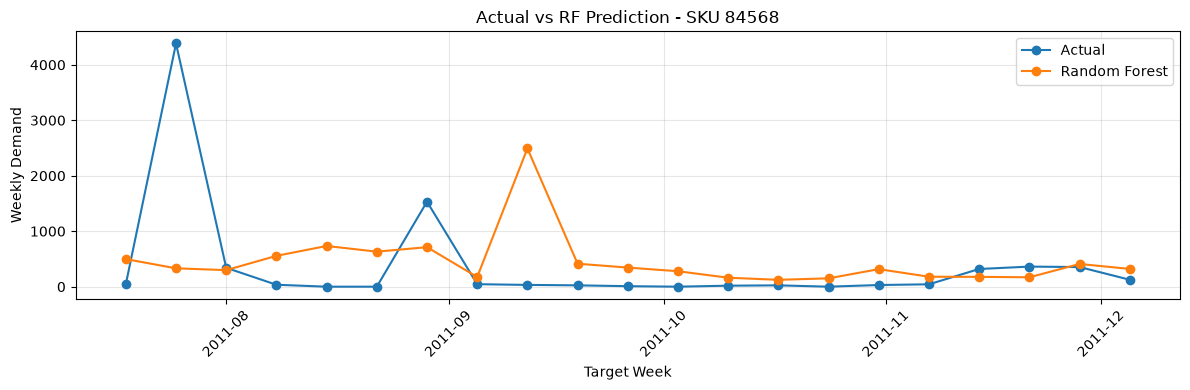

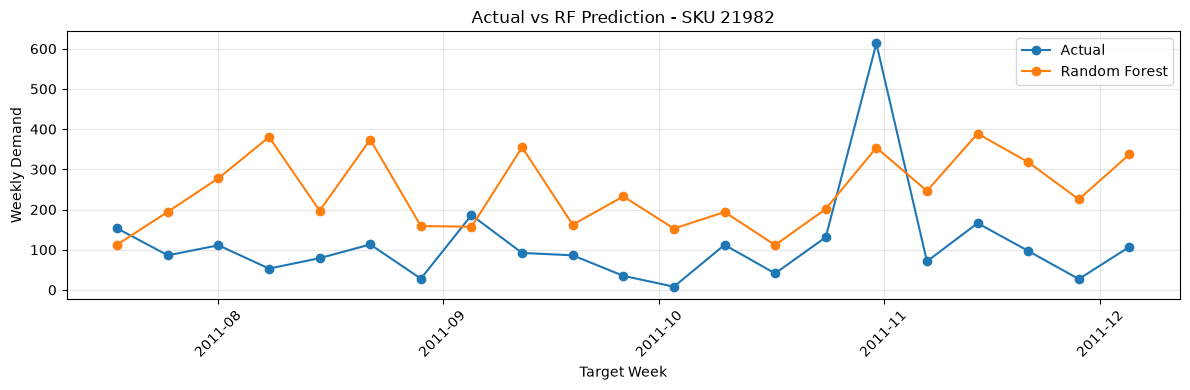

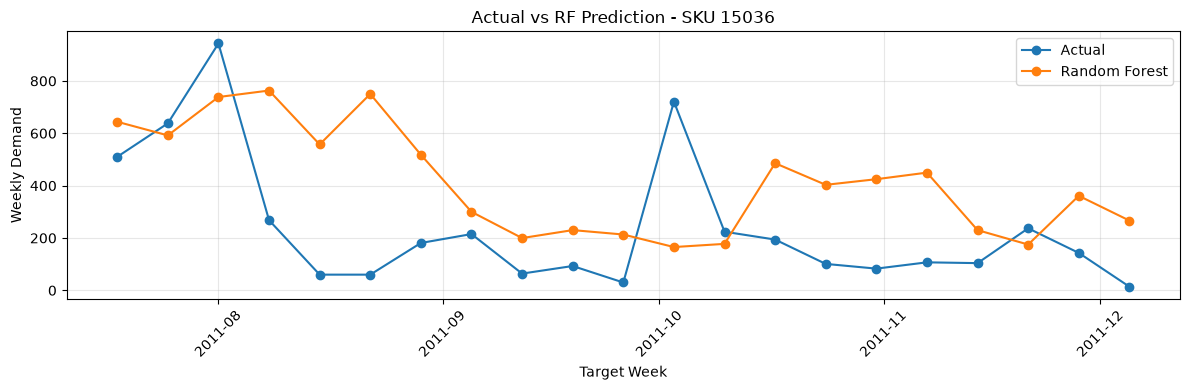

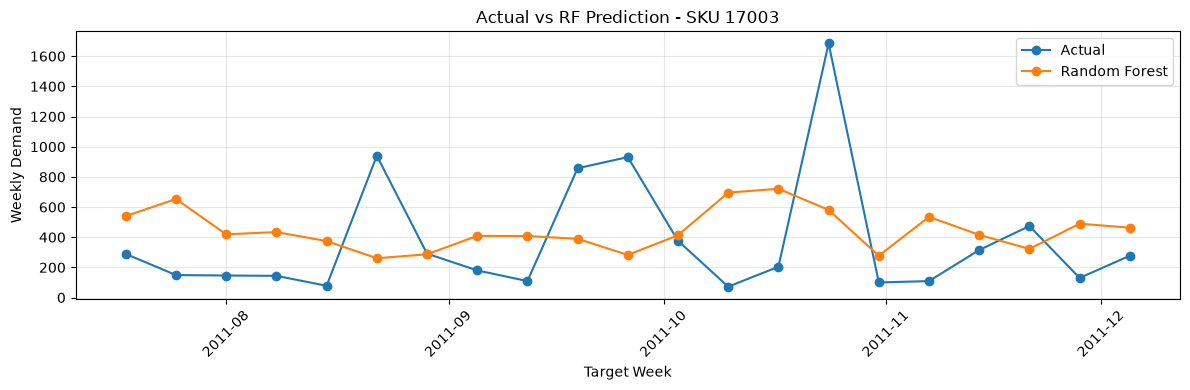

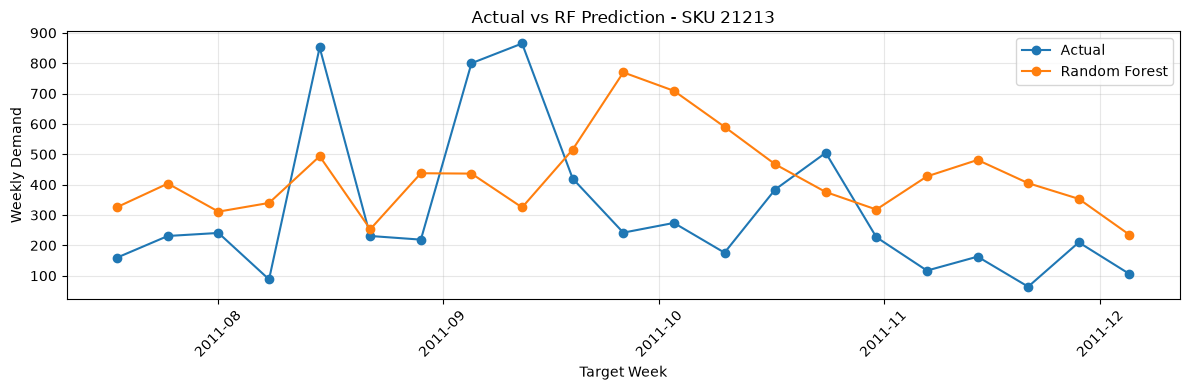

In [22]:
import matplotlib.pyplot as plt

for sku in worst_skus:
    plot_df = worst_df[
        worst_df["StockCode"].astype(str) == sku
    ].sort_values("Target_Week_Start")

    plt.figure(figsize=(12, 4))
    plt.plot(plot_df["Target_Week_Start"], plot_df["Target_Demand_Weekly"],
             marker="o", label="Actual")
    plt.plot(plot_df["Target_Week_Start"], plot_df["RF_Pred"],
             marker="o", label="Random Forest")

    plt.title(f"Actual vs RF Prediction - SKU {sku}")
    plt.xlabel("Target Week")
    plt.ylabel("Weekly Demand")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [23]:
demand_profile = (
    evaluation_df.groupby("StockCode")
    .agg(
        Total_Actual=("Target_Demand_Weekly", "sum"),
        Mean_Demand=("Target_Demand_Weekly", "mean"),
        Std_Demand=("Target_Demand_Weekly", "std"),
        Zero_Weeks=("Target_Demand_Weekly", lambda x: (x == 0).sum()),
        Max_Demand=("Target_Demand_Weekly", "max"),
        Median_Demand=("Target_Demand_Weekly", "median")
    )
    .reset_index()
)

demand_profile["Zero_Week_Rate"] = (
    demand_profile["Zero_Weeks"] / 21 * 100
)

demand_profile["CV"] = (
    demand_profile["Std_Demand"] /
    demand_profile["Mean_Demand"].replace(0, np.nan)
)

demand_profile["Peak_to_Median"] = (
    demand_profile["Max_Demand"] /
    demand_profile["Median_Demand"].replace(0, np.nan)
)

display(
    demand_profile[
        demand_profile["StockCode"].astype(str).isin(worst_skus)
    ].sort_values("CV", ascending=False)
)

,StockCode,Total_Actual,Mean_Demand,Std_Demand,Zero_Weeks,Max_Demand,Median_Demand,Zero_Week_Rate,CV,Peak_to_Median
12,84568,7720,367.619048,980.518306,4,4384,35.0,19.047619,2.667213,125.257143
1,17003,7855,374.047619,405.766494,0,1684,204.0,0.000000,1.084799,8.254902
7,21982,2395,114.047619,123.626242,0,613,92.0,0.000000,1.083988,6.663043
0,15036,4990,237.619048,251.609912,0,943,143.0,0.000000,1.058879,6.594406
4,21213,6575,313.095238,244.576349,0,865,231.0,0.000000,0.781156,3.744589


In [24]:
diagnostic_df = test_df.select([
    "StockCode", "Target_Week_Start",
    "Weekly_Demand", "Lag_1W", "Lag_2W", "Lag_4W",
    "Rolling_Mean_4W", "Rolling_Std_4W",
    "Target_Demand_Weekly"
]).to_pandas()

diagnostic_df["RF_Pred"] = y_pred_rf

for sku in ["84568", "15036"]:
    print(f"\n===== SKU {sku} =====")
    display(
        diagnostic_df[
            diagnostic_df["StockCode"].astype(str) == sku
        ].sort_values("Target_Demand_Weekly", ascending=False).head(5)
    )


===== SKU 84568 =====


,StockCode,Target_Week_Start,Weekly_Demand,Lag_1W,Lag_2W,Lag_4W,Rolling_Mean_4W,Rolling_Std_4W,Target_Demand_Weekly,RF_Pred
253,84568,2011-07-25,44,583,8,328,301.75,235.420723,4384,331.037379
258,84568,2011-08-29,0,0,35,4384,1189.75,2134.967662,1532,712.430558
270,84568,2011-11-21,319,43,30,24,24.25,18.006943,362,169.722409
271,84568,2011-11-28,362,319,43,0,98.00,148.429557,354,409.629736
254,84568,2011-08-01,4384,44,583,288,230.75,265.738437,340,298.443697



===== SKU 15036 =====


,StockCode,Target_Week_Start,Weekly_Demand,Lag_1W,Lag_2W,Lag_4W,Rolling_Mean_4W,Rolling_Std_4W,Target_Demand_Weekly,RF_Pred
2,15036,2011-08-01,638,510,352,167,741.75,809.725211,943,738.504635
11,15036,2011-10-03,30,93,64,181,138.25,71.364674,721,165.415057
1,15036,2011-07-25,510,352,1938,169,656.50,858.725606,638,591.927299
0,15036,2011-07-18,352,1938,167,1285,889.75,875.004524,510,643.994331
3,15036,2011-08-08,943,638,510,1938,859.50,728.452927,268,763.276157


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

X_train_v3 = train_df.select(FEATURES + ["StockCode"]).to_pandas()
X_test_v3 = test_df.select(FEATURES + ["StockCode"]).to_pandas()

X_train_v3["StockCode"] = X_train_v3["StockCode"].astype(str)
X_test_v3["StockCode"] = X_test_v3["StockCode"].astype(str)

preprocessor = ColumnTransformer([
    ("sku_encoder", OneHotEncoder(handle_unknown="ignore"), ["StockCode"]),
    ("numeric", "passthrough", FEATURES)
])

rf_v3 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_v3.fit(X_train_v3, y_train)
y_pred_rf_v3 = rf_v3.predict(X_test_v3)

display(pd.DataFrame([
    evaluate_model("Naive Baseline", y_test, y_pred_baseline),
    evaluate_model("RF V2", y_test, y_pred_rf),
    evaluate_model("RF V3 + SKU", y_test, y_pred_rf_v3)
]))

,Model,MAE,RMSE,WAPE (%),Forecast Score (%),Bias (%)
0,Naive Baseline,365.055,667.304,67.583,32.417,-1.104
1,RF V2,332.708,557.053,61.595,38.405,5.838
2,RF V3 + SKU,327.580,550.413,60.646,39.354,5.595


In [26]:
evaluation_v3 = evaluation_df.copy()
evaluation_v3["RF_V3_Pred"] = y_pred_rf_v3

sku_comparison = evaluation_v3.groupby("StockCode").apply(
    lambda g: pd.Series({
        "Actual_Demand": g["Target_Demand_Weekly"].sum(),
        "RF_V2_WAPE": (
            np.abs(g["Target_Demand_Weekly"] - g["RF_Pred"]).sum()
            / g["Target_Demand_Weekly"].sum() * 100
        ),
        "RF_V3_WAPE": (
            np.abs(g["Target_Demand_Weekly"] - g["RF_V3_Pred"]).sum()
            / g["Target_Demand_Weekly"].sum() * 100
        )
    })
).reset_index()

sku_comparison["Improvement"] = (
    sku_comparison["RF_V2_WAPE"] - sku_comparison["RF_V3_WAPE"]
)

display(sku_comparison.sort_values("Improvement", ascending=False))

,StockCode,Actual_Demand,RF_V2_WAPE,RF_V3_WAPE,Improvement
7,21982,2395.0,141.633340,128.059952,13.573389
18,85099F,7238.0,77.937611,71.655065,6.282546
13,84755,5522.0,65.899918,61.680863,4.219055
4,21213,6575.0,78.824632,75.298578,3.526053
16,84992,4461.0,78.472460,75.130608,3.341852
8,22178,10283.0,58.942687,55.668021,3.274666
17,85099B,23602.0,52.165077,49.104535,3.060542
12,84568,7720.0,158.660516,155.984596,2.675920
19,85123A,13466.0,55.025279,52.449256,2.576023
10,22492,12305.0,67.376251,65.300500,2.075751


In [27]:
train_df = train_df.with_columns([
    pl.col("Target_Week_Start").dt.month().alias("Target_Month"),
    pl.col("Target_Week_Start").dt.quarter().alias("Target_Quarter"),
    pl.col("Target_Week_Start").dt.year().alias("Target_Year"),
    pl.col("Target_Week_Start").dt.month().is_in([11, 12])
      .cast(pl.Int32).alias("Target_Is_Peak_Season")
])

test_df = test_df.with_columns([
    pl.col("Target_Week_Start").dt.month().alias("Target_Month"),
    pl.col("Target_Week_Start").dt.quarter().alias("Target_Quarter"),
    pl.col("Target_Week_Start").dt.year().alias("Target_Year"),
    pl.col("Target_Week_Start").dt.month().is_in([11, 12])
      .cast(pl.Int32).alias("Target_Is_Peak_Season")
])

TARGET_CALENDAR_FEATURES = [
    "Target_Month", "Target_Quarter",
    "Target_Year", "Target_Is_Peak_Season"
]

FEATURES_V4 = FEATURES + TARGET_CALENDAR_FEATURES

X_train_v4 = train_df.select(FEATURES_V4 + ["StockCode"]).to_pandas()
X_test_v4 = test_df.select(FEATURES_V4 + ["StockCode"]).to_pandas()

X_train_v4["StockCode"] = X_train_v4["StockCode"].astype(str)
X_test_v4["StockCode"] = X_test_v4["StockCode"].astype(str)

rf_v4 = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("sku_encoder", OneHotEncoder(handle_unknown="ignore"), ["StockCode"]),
        ("numeric", "passthrough", FEATURES_V4)
    ])),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_v4.fit(X_train_v4, y_train)
y_pred_rf_v4 = rf_v4.predict(X_test_v4)

In [28]:
display(pd.DataFrame([
    evaluate_model("Naive Baseline", y_test, y_pred_baseline),
    evaluate_model("RF V2", y_test, y_pred_rf),
    evaluate_model("RF V3 + SKU", y_test, y_pred_rf_v3),
    evaluate_model("RF V4 + SKU + Target Calendar", y_test, y_pred_rf_v4)
]))

,Model,MAE,RMSE,WAPE (%),Forecast Score (%),Bias (%)
0,Naive Baseline,365.055,667.304,67.583,32.417,-1.104
1,RF V2,332.708,557.053,61.595,38.405,5.838
2,RF V3 + SKU,327.580,550.413,60.646,39.354,5.595
3,RF V4 + SKU + Target Calendar,325.290,541.799,60.222,39.778,6.393


In [31]:
evaluation_v4 = evaluation_df.copy()

evaluation_v4["RF_V3_Pred"] = y_pred_rf_v3
evaluation_v4["RF_V4_Pred"] = y_pred_rf_v4

sku_v4_comparison = evaluation_v4.groupby("StockCode").apply(
    lambda g: pd.Series({
        "Actual_Demand": g["Target_Demand_Weekly"].sum(),
        "RF_V3_WAPE": (
            np.abs(g["Target_Demand_Weekly"] - g["RF_V3_Pred"]).sum()
            / g["Target_Demand_Weekly"].sum() * 100
        ),
        "RF_V4_WAPE": (
            np.abs(g["Target_Demand_Weekly"] - g["RF_V4_Pred"]).sum()
            / g["Target_Demand_Weekly"].sum() * 100
        )
    })
).reset_index()

sku_v4_comparison["Improvement"] = (
    sku_v4_comparison["RF_V3_WAPE"] - sku_v4_comparison["RF_V4_WAPE"]
)

display(sku_v4_comparison.sort_values("Improvement", ascending=False))

,StockCode,Actual_Demand,RF_V3_WAPE,RF_V4_WAPE,Improvement
0,15036,4990.0,116.742487,112.514751,4.227736
14,84879,19958.0,55.089917,51.547429,3.542488
12,84568,7720.0,155.984596,153.102567,2.882029
17,85099B,23602.0,49.104535,46.999283,2.105252
5,21232,4926.0,48.960284,47.313495,1.646789
15,84991,7458.0,61.496925,60.357912,1.139012
4,21213,6575.0,75.298578,74.368079,0.930499
9,22197,35258.0,44.350235,43.494366,0.855869
2,20725,8703.0,34.123928,33.425011,0.698917
1,17003,7855.0,96.021395,95.431159,0.590236
